# D-01: Stored plate-reader fluorescence signals

**Task:** Recover and describe each stored plate-reader result.

**Inputs:** Three original VMR results, VWP protocol and experiment notes.

**Motivation:** Make the recorded numerical signals usable for further analysis.

**Goal:** Export physical-well readings, gain-specific summaries and maps.

**Prediction:** Different gain settings will produce different native signal distributions.

In [1]:
from pathlib import Path
import hashlib, json, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import gzip, re
from matplotlib.colors import Normalize

# Locate the shared data folder when Jupyter starts inside a task folder.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "data/input").is_dir() and (p / "tasks").is_dir())
INPUT = ROOT / "data/input"
OUTPUT = ROOT / "data/output/D-01"
OUTPUT.mkdir(parents=True, exist_ok=True)
RESULT_FILES = sorted(INPUT.glob("*.vmr"))
PROTOCOL_FILE = INPUT / "iGEM Calcium GFP.vwp"
NOTES_FILE = INPUT / "cadmium_experiment_notes.md"
INPUT_FILES = [*RESULT_FILES, PROTOCOL_FILE, NOTES_FILE]
LITERAL_VALUE = 260000  # A repeated stored number; its vendor meaning is unconfirmed.
assert len(RESULT_FILES) == 3, "Expected the three supplied result files."
plt.rcParams.update({"font.size": 9, "font.family": "DejaVu Sans",
    "axes.spines.top": False, "axes.spines.right": False,
    "savefig.dpi": 300, "svg.fonttype": "none"})


## Materials and methods

Decompress the VMR JSON and preserve its separate trailer. Assign each value using the explicit row and column arrays; retain GUID and gain. Plot each result on its own native-value colour scale and count exact occurrences of 260000. The VWP supplies protocol context. Source: cadmium_experiment_notes.md, R-WET-12AUG-VOYAGER and R-WET-12AUG-LAYOUT.

**Scope and working assumptions.** Each VMR GUID and gain defines a separate stored result set. Explicit file coordinates define the wells, and values retain their native scale. The archive has no accepted well-to-clone/dose/control map or gain/flag calibration; source records also differ in instrument naming. This analysis reports native signals without blank, biomass or dose-response correction.

In [2]:
rows, runs = [], []
for path in RESULT_FILES:
    text = gzip.decompress(path.read_bytes()).decode("utf-8-sig")
    obj, end = json.JSONDecoder().raw_decode(text)
    assert re.fullmatch(r"[0-9A-Fa-f]{64}", text[end:].strip())
    result = obj[0]["ProtocolResult"]
    statement = result["WorkflowPlan"]["WorkflowStatements"][0]
    data, method = statement["Data"], statement["Measurements"][0]
    assert result["UsedMeasurementTypesDb"] == "Fluorescence"
    assert data["CompletedEntries"] == data["ExpectedEntries"] == 50
    assert data["Dimensions"]["Cycles"] == data["Dimensions"]["Chromatics"] == 1
    entries = data["Data"]
    while isinstance(entries, list) and len(entries) == 1:
        entries = entries[0]
    assert len(entries) == len(data["RowIndices"]) == len(data["ColumnIndices"]) == 50
    gain = method["Gain"]
    values, wells = [], set()
    for ri, ci, value in zip(data["RowIndices"], data["ColumnIndices"], entries):
        while isinstance(value, list):
            assert len(value) == 1
            value = value[0]
        assert isinstance(value, (int, float)) and not isinstance(value, bool)
        well = f"{chr(64 + ri)}{ci}"
        assert well not in wells
        wells.add(well)
        values.append(value)
        rows.append({"file": path.name, "result_id": result["Guid"], "well": well,
                     "row": ri, "column": ci, "native_value": value,
                     "gain": gain["Value"], "condition": "unknown"})
    assert wells == {f"{r}{c}" for r in "ABCDE" for c in range(1, 11)}
    runs.append({"result_id": result["Guid"], "file": path.name,
        "timestamp_utc": result["UtcDateTime"], "gain": gain["Value"],
        "gain_type": gain["$type"].split(",")[0].split(".")[-1],
        "n_wells": len(values), "minimum": min(values), "median": float(np.median(values)),
        "maximum": max(values), "count_260000": values.count(LITERAL_VALUE),
        "reader_serial": result["ReaderSerial"], "channel": method["DetectionChannel"],
        "excitation_field": method["FilterSettings"]["MonochromatorSettings"]["ExcitationFilter"]["Wavelength"],
        "emission_field": method["FilterSettings"]["MonochromatorSettings"]["EmissionFilter"]["Wavelength"]})
values = pd.DataFrame(rows)
run_table = pd.DataFrame(runs).sort_values("timestamp_utc").reset_index(drop=True)
assert len(values) == 150 and run_table.result_id.nunique() == 3
values.to_csv(OUTPUT / "plate_readings_unmapped.csv", index=False)
run_table.to_csv(OUTPUT / "run_summary.csv", index=False)


## Results

,gain,n_wells,minimum,median,maximum,count_260000,Input data,Finished without more wet-lab data?
0,2976,50,27641,195949.0,260000,13,Original VMR files,Yes: raw description
1,2939,50,23036,260000.0,260000,29,Original VMR files,Yes: raw description
2,933,50,22,110.0,3328,0,Original VMR files,Yes: raw description


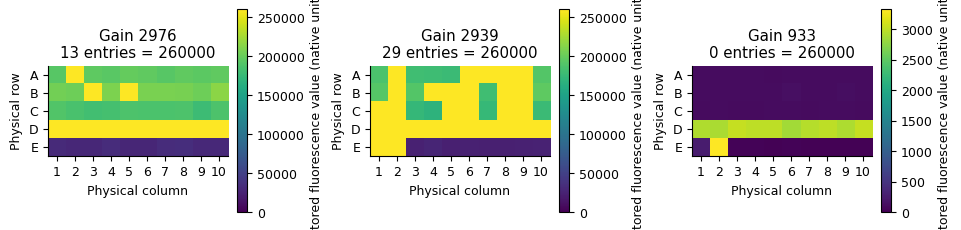

In [3]:
# Each panel has its own scale because the gains are different.
fig, axes = plt.subplots(1, 3, figsize=(9.5, 3.2), constrained_layout=True)
for ax, row in zip(axes, run_table.to_dict("records")):
    part = values[values.result_id == row["result_id"]]
    matrix = part.pivot(index="row", columns="column", values="native_value").to_numpy()
    im = ax.imshow(matrix, cmap="viridis", norm=Normalize(0, row["maximum"]), aspect="equal")
    ax.set(xticks=range(10), xticklabels=range(1, 11), yticks=range(5),
           yticklabels=list("ABCDE"), xlabel="Physical column", ylabel="Physical row",
           title=f"Gain {row['gain']}\n{row['count_260000']} entries = 260000")
    fig.colorbar(im, ax=ax, shrink=0.65, label="Stored fluorescence value (native units)")
fig.savefig(OUTPUT / "plate_signals.png", dpi=300)
fig.savefig(OUTPUT / "plate_signals.svg")
display(Markdown("## Results"))
display(run_table[["gain", "n_wells", "minimum", "median", "maximum", "count_260000"]]
    .assign(**{"Input data": "Original VMR files", "Finished without more wet-lab data?": "Yes: raw description"}))
display(fig)
plt.close(fig)
summary = {
 "title": "D-01: Stored plate-reader fluorescence signals",
 "question": "What numerical and spatial patterns are present in the supplied native results?",
 "materials": ["Three original VMR result files, one VWP protocol and source-specific cadmium experiment notes."],
 "methods": ["Decompress JSON and map values with the stored physical row/column indices. Summarize each GUID/gain separately.",
             "Plot independent native-value colour scales. No gain conversion, condition assignment, blank or OD correction."],
 "results": [f"Recovered {len(values)} readings across {len(run_table)} distinct stored results, with 50 physical wells A1:E10 each.",
             "; ".join(f"gain {r['gain']}: range {r['minimum']:g}-{r['maximum']:g}, {r['count_260000']}/50 entries equal 260000" for r in runs) + "."],
 "conclusion": (f"The three stored result sets contain {len(values)} readings across wells A1-E10. "
              "Native signals vary across wells and gain settings. The exported readings and coordinates provide a reproducible numerical record of the plate measurements."),
 "limitations": [],
 "figures": [{"file": "plate_signals.png", "caption": "Stored fluorescence by physical well. Each result uses its own colour scale; gains differ. No condition labels or uncertainty estimates are assigned."}],
 "references": ["Original VMR ProtocolResult fields and cadmium_experiment_notes.md: R-WET-12AUG-VOYAGER / R-WET-12AUG-LAYOUT."],
 "table": {"columns": ["Gain", "Wells", "Median", "260000 count", "Input data", "Finished without more wet-lab data?"],
           "rows": [[str(r["gain"]), str(r["n_wells"]), f"{r['median']:g}", str(r["count_260000"]), "Original VMR files", "Yes: raw description"] for r in run_table.to_dict("records")]}}
summary["scope_and_assumptions"] = 'Each VMR GUID and gain defines a separate stored result set. Explicit file coordinates define the wells, and values retain their native scale. The archive has no accepted well-to-clone/dose/control map or gain/flag calibration; source records also differ in instrument naming. This analysis reports native signals without blank, biomass or dose-response correction.'
summary.pop("limitations", None)
(OUTPUT / "summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8");

In [4]:
display(Markdown("## Conclusion and interpretation\n\n" + summary["conclusion"]))
(OUTPUT / "conclusion.md").write_text(summary["conclusion"], encoding="utf-8")
# Record the source bytes and software used for this calculation.
provenance = {"inputs": {p.name: hashlib.sha256(p.read_bytes()).hexdigest()
                           for p in INPUT_FILES},
    "python": platform.python_version(), "numpy": np.__version__,
    "pandas": pd.__version__, }
(OUTPUT / "provenance.json").write_text(json.dumps(provenance, indent=2), encoding="utf-8");

## Conclusion and interpretation

The three stored result sets contain 150 readings across wells A1-E10. Native signals vary across wells and gain settings. The exported readings and coordinates provide a reproducible numerical record of the plate measurements.